<a href="https://colab.research.google.com/github/jmorote-debug/oracle-database-lab/blob/main/IC_Pr%C3%A1ctica_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

___
# Cargar datos (train.csv y test.csv)
___

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt

In [ ]:
path = path = "/content/train-1.csv"
path2 = path2 = "/content/test-1.csv"
df = pd.read_csv(path)
df2 = pd.read_csv(path2)

## Vista rápida de train-1.csv

In [ ]:
display(df.head())
print("Columnas:", list(df.columns))
print("Filas x Columnas:", df.shape)

,id,category,brand,brand_tier,material,season,channel,country,weight_kg,rating,reviews,shipping_cost,margin,discount,is_promo,price
0,0,Juguetes,MarcaD,Media,Madera,Invierno,Online,FR,0.863,3.45,72,6.31,0.283,0.178,0,143.65
1,1,Hogar,MarcaF,Budget,Metal,Otoño,Retail,ES,0.852,3.94,14,2.75,0.174,0.142,0,77.09
2,2,Juguetes,MarcaB,Premium,Plástico,Primavera,Online,ES,0.869,4.67,97,5.13,0.246,0.197,1,77.58
3,3,Deporte,MarcaA,Premium,Plástico,Verano,Online,ES,0.799,4.57,84,1.41,0.071,0.095,0,127.23
4,4,Electrónica,MarcaE,Budget,Plástico,Otoño,Retail,ES,0.410,3.46,47,2.36,0.230,0.173,0,127.18


Columnas: ['id', 'category', 'brand', 'brand_tier', 'material', 'season', 'channel', 'country', 'weight_kg', 'rating', 'reviews', 'shipping_cost', 'margin', 'discount', 'is_promo', 'price']
Filas x Columnas: (8000, 16)


## Vista rápida de test-1.csv

In [ ]:
display(df2.head())
print("Columnas:", list(df2.columns))
print("Filas x Columnas:", df2.shape)

,id,category,brand,brand_tier,material,season,channel,country,weight_kg,rating,reviews,shipping_cost,margin,discount,is_promo
0,8000,Hogar,MarcaD,Media,Vidrio,Primavera,Online,ES,0.202,3.35,69,3.20,0.325,0.180,0
1,8001,Belleza,MarcaE,Budget,Plástico,Invierno,Retail,FR,1.115,3.09,17,2.78,0.255,0.101,0
2,8002,Moda,MarcaB,Premium,Metal,Primavera,Online,ES,2.445,4.57,186,3.42,0.457,0.233,1
3,8003,Electrónica,MarcaF,Budget,Plástico,Primavera,Retail,PT,0.207,5.00,13,2.08,0.215,0.170,0
4,8004,Electrónica,MarcaD,Media,Textil,Verano,Online,IT,0.216,4.77,21,2.75,0.198,0.211,1


Columnas: ['id', 'category', 'brand', 'brand_tier', 'material', 'season', 'channel', 'country', 'weight_kg', 'rating', 'reviews', 'shipping_cost', 'margin', 'discount', 'is_promo']
Filas x Columnas: (2000, 15)


___
# Análisis exploratorio (EDA)
___

## 1. Exploración inicial

> Información general del conjunto

In [ ]:
print("INFORMACIÓN DEL DATASET DE ENTRENAMIENTO")
df.info()

print("\nINFORMACIÓN DEL DATASET DE PRUEBA")
df2.info()


INFORMACIÓN DEL DATASET DE ENTRENAMIENTO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             8000 non-null   int64  
 1   category       8000 non-null   object 
 2   brand          8000 non-null   object 
 3   brand_tier     8000 non-null   object 
 4   material       7748 non-null   object 
 5   season         8000 non-null   object 
 6   channel        8000 non-null   object 
 7   country        8000 non-null   object 
 8   weight_kg      8000 non-null   float64
 9   rating         8000 non-null   float64
 10  reviews        8000 non-null   int64  
 11  shipping_cost  8000 non-null   float64
 12  margin         8000 non-null   float64
 13  discount       8000 non-null   float64
 14  is_promo       8000 non-null   int64  
 15  price          8000 non-null   float64
dtypes: float64(6), int64(3), object(7)
memory usage: 1000.1

> Detectar valores ausentes

In [ ]:
nulos = pd.DataFrame({
    "Train": df.isnull().sum(),
    "Test": df2.isnull().sum()
})

display(nulos)


,Train,Test
brand,0,0.0
brand_tier,0,0.0
category,0,0.0
channel,0,0.0
country,0,0.0
discount,0,0.0
id,0,0.0
is_promo,0,0.0
margin,0,0.0
material,252,58.0


> Comrpobar consistencia de los ID

In [ ]:
print("IDs duplicados en entrenamiento:", df["id"].duplicated().sum())

print("IDs duplicados en prueba:", df2["id"].duplicated().sum())

print("Filas completamente duplicadas en train:", df.duplicated().sum())


IDs duplicados en entrenamiento: 0
IDs duplicados en prueba: 0
Filas completamente duplicadas en train: 0


## 2. Análisis de la variable objetivo `price`

> Estadísticas descriptivas de los precios

In [ ]:
print("Estadísticas de PRICE:")
display(df["price"].describe())

# Medida de asimetría
print("Asimetría:", df["price"].skew())

Estadísticas de PRICE:


,price
count,8000.000000
mean,158.001226
std,78.668396
min,29.960000
25%,108.457500
50%,139.825000
75%,186.922500
max,1238.250000


Asimetría: 2.885315933445061


> Histograma de distribución de los precios

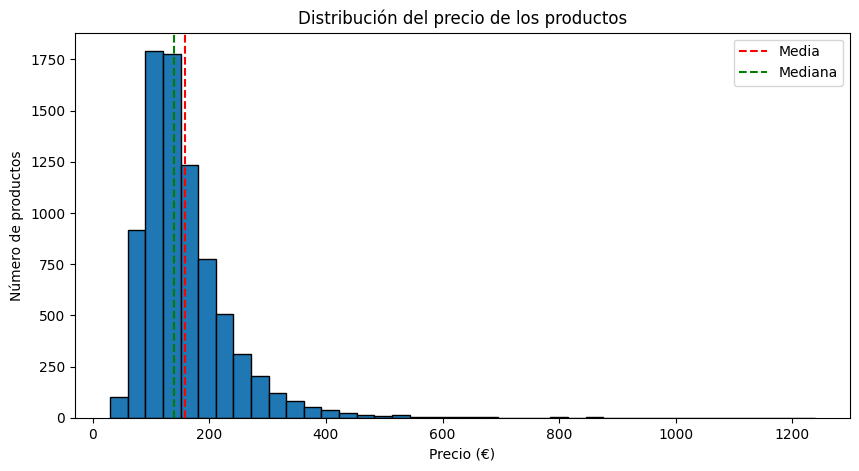

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df["price"], bins=40, edgecolor="black")
plt.axvline(df["price"].mean(), color="red", linestyle="--", label="Media")
plt.axvline(df["price"].median(), color="green", linestyle="--", label="Mediana")

plt.title("Distribución del precio de los productos")
plt.xlabel("Precio (€)")
plt.ylabel("Número de productos")
plt.legend()
plt.show()


> Diagrama de caja de la variable price

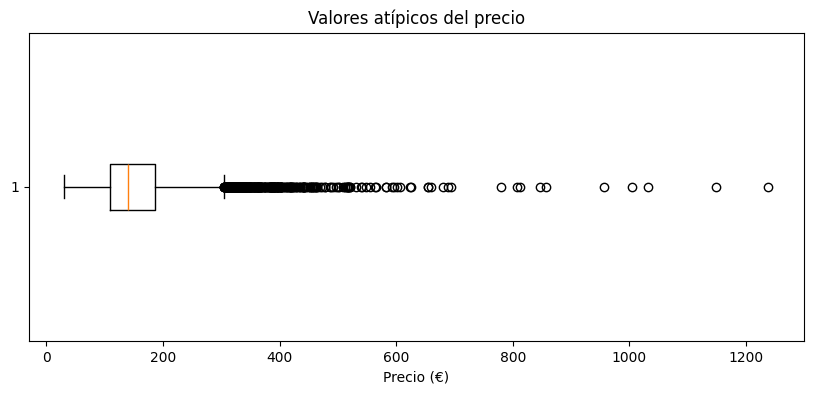

In [ ]:
plt.figure(figsize=(10, 4))

plt.boxplot(df["price"], vert=False)

plt.title("Valores atípicos del precio")
plt.xlabel("Precio (€)")
plt.show()


## 3. Análisis de variables categóricas

> Precio según categoría

In [ ]:
# Estadísticas del precio según categoría
precios_categoria = df.groupby("category")["price"].agg(
    ["count", "mean", "median"]
)

# Ordenar por precio medio
precios_categoria = precios_categoria.sort_values(
    by="mean", ascending=False
)

display(precios_categoria.round(2))


,count,mean,median
category,,,
Electrónica,1642,184.92,164.96
Hogar,1629,165.11,146.58
Deporte,1171,154.88,137.26
Juguetes,1026,144.83,128.33
Moda,1752,144.76,131.50
Belleza,780,138.24,125.35


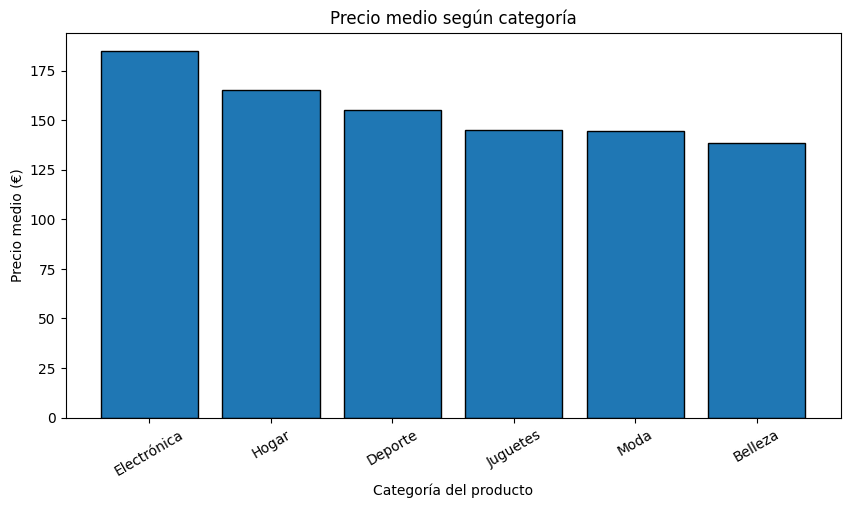

In [ ]:
# Comparación del precio medio por categoría
plt.figure(figsize=(10, 5))

plt.bar(
    precios_categoria.index,
    precios_categoria["mean"],
    edgecolor="black"
)

plt.title("Precio medio según categoría")
plt.xlabel("Categoría del producto")
plt.ylabel("Precio medio (€)")

plt.xticks(rotation=30)
plt.show()

> Relación entre gama de marca y precio

In [ ]:
precios_gama = df.groupby("brand_tier")["price"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(precios_gama.round(2))

,count,mean,median,std,min,max
brand_tier,,,,,,
Budget,2731,142.86,129.99,61.77,38.56,547.51
Media,2894,158.18,140.01,77.77,41.78,1031.40
Premium,2375,175.19,155.94,92.38,29.96,1238.25


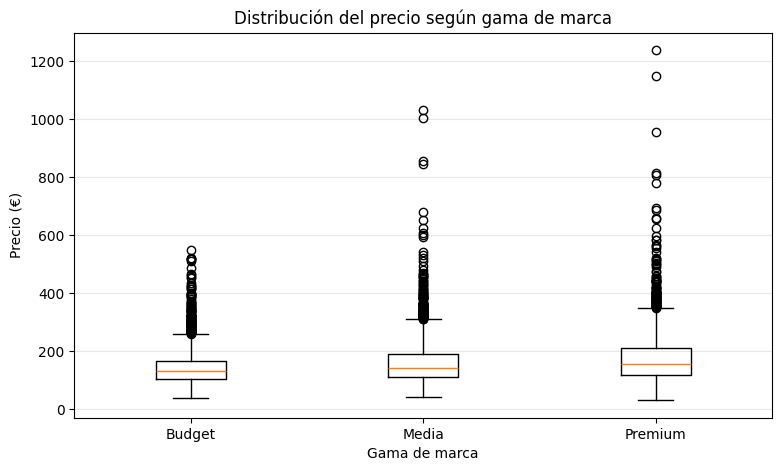

In [ ]:
gamas = ["Budget", "Media", "Premium"]

datos = [
    df.loc[df["brand_tier"] == gama, "price"]
    for gama in gamas
]

# Crear el diagrama de caja
plt.figure(figsize=(9, 5))
plt.boxplot(datos)

plt.xticks([1, 2, 3], gamas)
plt.title("Distribución del precio según gama de marca")
plt.xlabel("Gama de marca")
plt.ylabel("Precio (€)")
plt.grid(axis="y", alpha=0.3)

plt.show()

## 4. Análisis de variables numéricas

In [ ]:
numericas = [
    "weight_kg",
    "rating",
    "reviews",
    "shipping_cost",
    "margin",
    "discount"
]

display(df[numericas].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
weight_kg,8000.0,1.11,1.06,0.05,0.47,0.80,1.37,21.51
rating,8000.0,4.09,0.49,2.15,3.76,4.10,4.43,5.00
reviews,8000.0,100.42,110.41,3.00,36.00,67.00,123.00,1578.00
shipping_cost,8000.0,3.37,1.26,0.00,2.52,3.36,4.22,7.97
margin,8000.0,0.28,0.08,0.05,0.22,0.28,0.33,0.58
discount,8000.0,0.17,0.07,0.00,0.12,0.16,0.22,0.45


> Correlación entre las variables numéricas y el precio

In [ ]:
correlaciones = df[numericas + ["price"]].corr()["price"]

correlaciones = correlaciones.drop("price")

correlaciones = correlaciones.sort_values(ascending=False)

display(correlaciones.round(3))

,price
weight_kg,0.569
shipping_cost,0.365
margin,0.240
reviews,0.108
rating,0.101
discount,-0.160


> Relación entre peso y precio

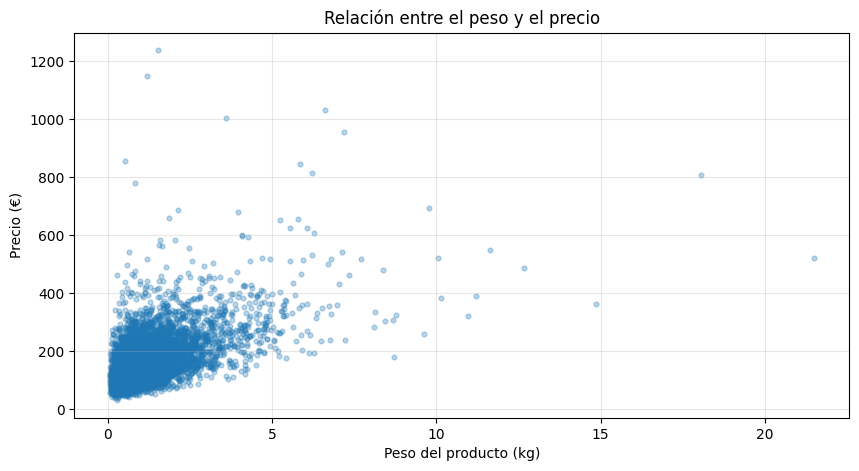

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["weight_kg"],
    df["price"],
    alpha=0.3,
    s=12
)

plt.title("Relación entre el peso y el precio")
plt.xlabel("Peso del producto (kg)")
plt.ylabel("Precio (€)")
plt.grid(alpha=0.3)

plt.show()

## 5. Matriz de correlaciones

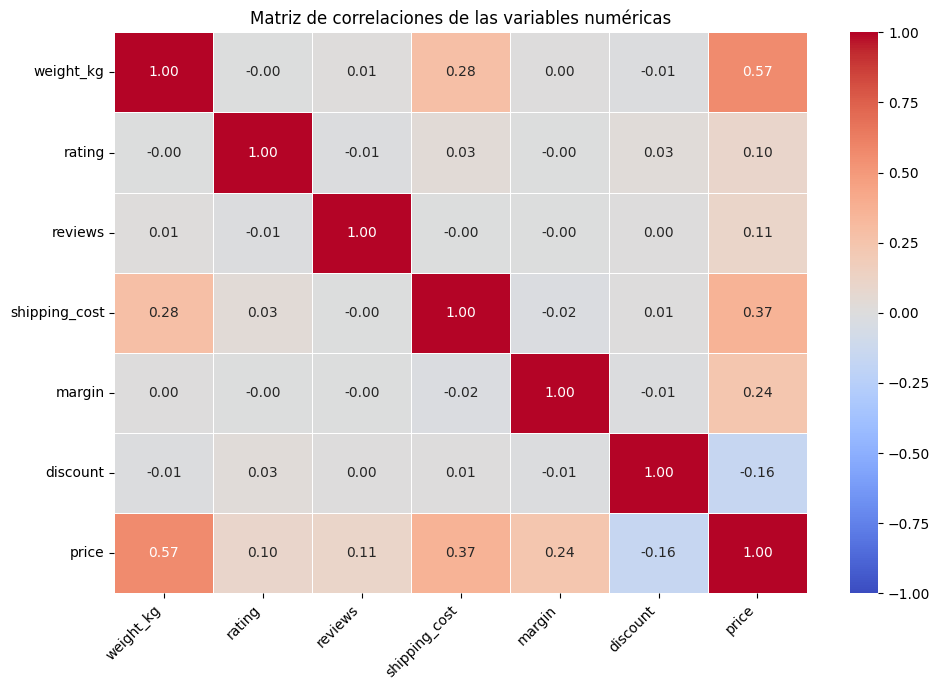

In [ ]:
variables = [
    "weight_kg",
    "rating",
    "reviews",
    "shipping_cost",
    "margin",
    "discount",
    "price"
]

# Calcular matriz de correlaciones
matriz_corr = df[variables].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Matriz de correlaciones de las variables numéricas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

___
# Pipeline
___

## Preprocesado

In [ ]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Cargar los datos (si no lo tenéis ya en una celda superior)
df = pd.read_csv("train-1.csv")

# Separar variables predictoras (X) y variable objetivo (y)
X = df.drop(columns=['id', 'price'])
y = df['price']

# Definir tipos de columnas
numeric_features = ['weight_kg', 'rating', 'reviews', 'shipping_cost', 'margin', 'discount', 'is_promo']
categorical_features = ['category', 'brand', 'brand_tier', 'material', 'season', 'channel', 'country']

# Crear transformadores
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Rellena los nulos de 'material'
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Unir todo en el preprocesador
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

## Entrenamiento del modelo

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Construir el Pipeline 1 uniendo el preprocesador y el modelo base
pipeline_1 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

## Cross-validation

In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

# Evaluar el modelo con validación cruzada (5 particiones)
scores = cross_val_score(pipeline_1, X, y, cv=5, scoring='neg_root_mean_squared_error')

# Convertir a positivo y calcular la media
rmse_scores = -scores
rmse_mean = rmse_scores.mean()

print(f"RMSE por partición: {np.round(rmse_scores, 2)}")
print(f"RMSE medio (Pipeline 1): {rmse_mean:.2f}")

RMSE por partición: [62.72 55.16 54.29 50.23 56.7 ]
RMSE medio (Pipeline 1): 55.82


___
# Ajustar parámetros (Tuning)
___

___
# Predicciones para test.csv
___

___
# Fichero submission.csv
___